# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:**Meraj Ali
- **Roll No:**023-24-0245
- **Section:**G
- **Date:** 16-11-2026
- **GitHub:**(https://github.com/rajamerajali/ML_Labs)
- **Kaggle:**

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

iris = load_iris()
print("Libraries loaded. Iris shape:", iris.data.shape)

Libraries loaded. Iris shape: (150, 4)


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

print("Slide 16:", predict([0.6, 0.8], [2, 3], -2))
w_check, b_check = [1, -0.5], 0.5
inputs = [[1, 1], [2, 1], [0, 3]]
print("Slide 17 predictions:", [predict(w_check, x, b_check) for x in inputs])

Slide 16: 1
Slide 17 predictions: [1, 1, 0]


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
X_and = np.array([[0,0], [0,1], [1,0], [1,1]])
y_and = np.array([0,0,0,1])
w = np.array([0.2, -0.1], dtype=float)
b = 0.0
eta = 0.1
mistakes = 0

print("One epoch on AND gate")
for x, y_true in zip(X_and, y_and):
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    error = y_true - y_hat
    if error != 0:
        mistakes += 1
        w = w + eta * error * x
        b = b + eta * error
    print(f"x={x}, y={y_true}, z={z:.3f}, y_hat={y_hat}, e={error}, updated w={w}, b={b:.3f}")

print("Final w:", w, "| final b:", b, "| mistakes:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")

One epoch on AND gate
x=[0 0], y=0, z=0.000, y_hat=1, e=-1, updated w=[ 0.2 -0.1], b=-0.100
x=[0 1], y=0, z=-0.200, y_hat=0, e=0, updated w=[ 0.2 -0.1], b=-0.100
x=[1 0], y=0, z=0.100, y_hat=1, e=-1, updated w=[ 0.1 -0.1], b=-0.200
x=[1 1], y=1, z=-0.200, y_hat=0, e=1, updated w=[0.2 0. ], b=-0.100
Final w: [0.2 0. ] | final b: -0.1 | mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    w = np.zeros(X.shape[1], dtype=float)
    b = 0.0
    mistakes_history = []

    for epoch in range(max_epochs):
        mistakes = 0
        for x_i, y_i in zip(X, y):
            y_hat = step_function(np.dot(w, x_i) + b)
            error = y_i - y_hat
            if error != 0:
                w += eta * error * x_i
                b += eta * error
                mistakes += 1
        mistakes_history.append(mistakes)
        if mistakes == 0:
            break
    return w, b, mistakes_history

X_or = np.array([[0,0], [0,1], [1,0], [1,1]])
y_or = np.array([0,1,1,1])
w_or, b_or, mistakes_or = train_perceptron(X_or, y_or)
print("OR gate weights:", w_or)
print("OR gate bias:", b_or)
print("Mistakes per epoch:", mistakes_or)

OR gate weights: [0.1 0.1]
OR gate bias: -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

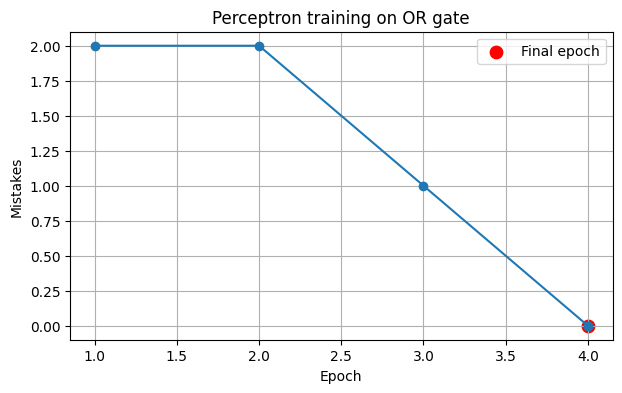

In [5]:
plt.figure()
plt.plot(range(1, len(mistakes_or)+1), mistakes_or, marker="o")
plt.scatter(len(mistakes_or), mistakes_or[-1], color="red", s=80, label="Final epoch")
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.legend()
plt.show()

**Interpretation:** The number of mistakes decreases as the perceptron adjusts its weights. The OR gate is linearly separable, so training reaches an epoch with zero mistakes and stops.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

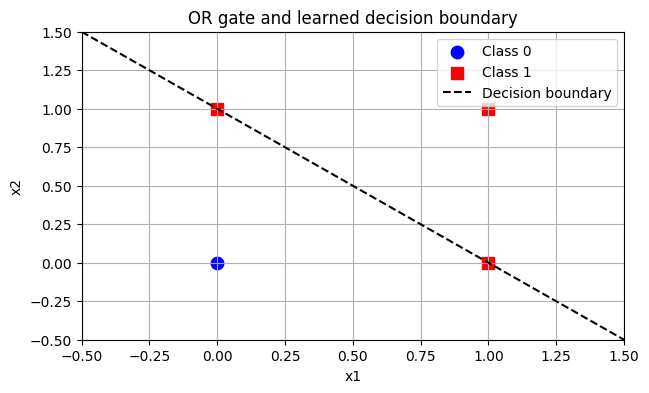

The perceptron predicts class 1 on the side where w·x + b >= 0.


In [6]:
def plot_boundary(ax, w, b, x_min=-0.5, x_max=1.5):
    w = np.asarray(w, dtype=float)
    if abs(w[1]) > 1e-12:
        x1 = np.linspace(x_min, x_max, 100)
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, "k--", label="Decision boundary")
    elif abs(w[0]) > 1e-12:
        x1_vertical = -b / w[0]
        ax.axvline(x1_vertical, color="black", linestyle="--", label="Decision boundary")
    else:
        ax.text(0.5, 0.5, "No boundary (zero weights)", transform=ax.transAxes, ha="center")

fig, ax = plt.subplots()
for cls, color, marker, label in [(0, "blue", "o", "Class 0"), (1, "red", "s", "Class 1")]:
    ax.scatter(X_or[y_or==cls, 0], X_or[y_or==cls, 1], c=color, marker=marker, label=label, s=80)
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("OR gate and learned decision boundary")
ax.legend()
plt.show()

print("The perceptron predicts class 1 on the side where w·x + b >= 0.")

**Interpretation:** The black dashed line is where the weighted sum equals zero. The perceptron predicts class 1 on the side where the weighted sum is non-negative, and class 0 on the other side.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

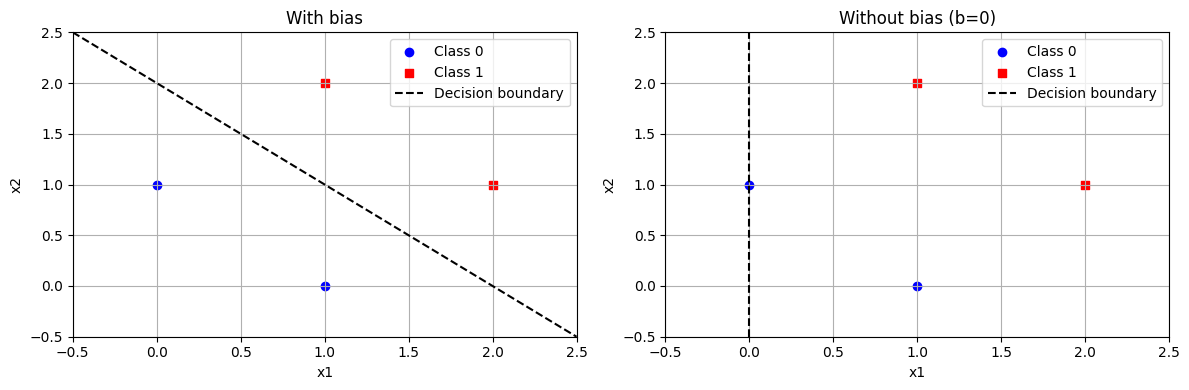

With-bias mistakes: [2, 3, 1, 0] | converged: True
No-bias mistakes: [3, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2] | converged: False


In [7]:
def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    w = np.zeros(X.shape[1], dtype=float)
    b = 0.0
    history = []
    for _ in range(max_epochs):
        mistakes = 0
        for x_i, y_i in zip(X, y):
            y_hat = step_function(np.dot(w, x_i))  # bias fixed at zero
            error = y_i - y_hat
            if error != 0:
                w += eta * error * x_i
                mistakes += 1
        history.append(mistakes)
        if mistakes == 0:
            break
    return w, b, history

X_bias = np.array([[1,0], [0,1], [2,1], [1,2]], dtype=float)
y_bias = np.array([0,0,1,1])
w_b, b_b, hist_b = train_perceptron(X_bias, y_bias)
w_nb, b_nb, hist_nb = train_perceptron_no_bias(X_bias, y_bias)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, w_plot, b_plot, title in [
    (axes[0], w_b, b_b, "With bias"),
    (axes[1], w_nb, b_nb, "Without bias (b=0)")
]:
    for cls, color, marker, label in [(0, "blue", "o", "Class 0"), (1, "red", "s", "Class 1")]:
        ax.scatter(X_bias[y_bias==cls,0], X_bias[y_bias==cls,1], c=color, marker=marker, label=label)
    plot_boundary(ax, w_plot, b_plot, x_min=-0.5, x_max=2.5)
    ax.set_xlim(-0.5, 2.5); ax.set_ylim(-0.5, 2.5)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(title); ax.legend()
plt.tight_layout()
plt.show()

print("With-bias mistakes:", hist_b, "| converged:", hist_b[-1] == 0)
print("No-bias mistakes:", hist_nb, "| converged:", hist_nb[-1] == 0)

**Interpretation:** The bias-enabled model can shift its boundary away from the origin. The no-bias model keeps the boundary passing through the origin and, for this dataset, does not converge to a zero-mistake solution.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final epoch mistakes: 4
Final weights: [-0.1  0. ]
Final bias: 0.0


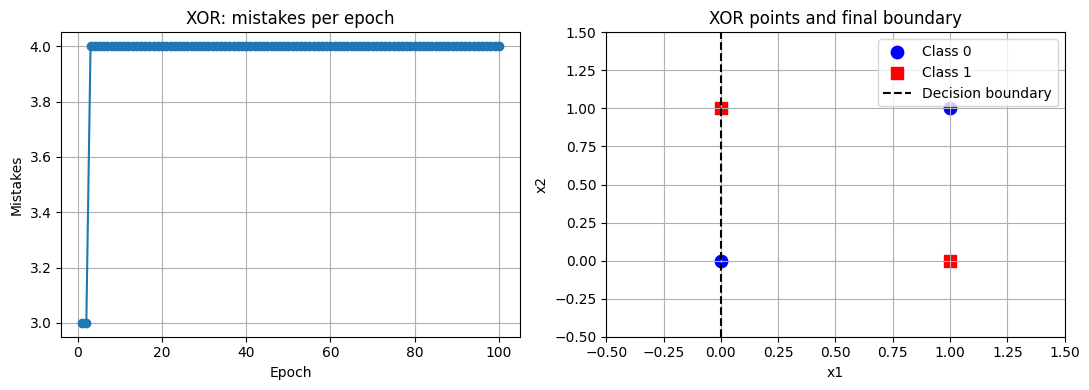

In [8]:
X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0,1,1,0])
w_xor, b_xor, mistakes_xor = train_perceptron(X_xor, y_xor, max_epochs=100)

print("Final epoch mistakes:", mistakes_xor[-1])
print("Final weights:", w_xor)
print("Final bias:", b_xor)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(mistakes_xor)+1), mistakes_xor, marker="o")
axes[0].set_title("XOR: mistakes per epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Mistakes")
for cls, color, marker, label in [(0, "blue", "o", "Class 0"), (1, "red", "s", "Class 1")]:
    axes[1].scatter(X_xor[y_xor==cls,0], X_xor[y_xor==cls,1], c=color, marker=marker, s=80, label=label)
plot_boundary(axes[1], w_xor, b_xor, x_min=-0.5, x_max=1.5)
axes[1].set_xlim(-0.5,1.5); axes[1].set_ylim(-0.5,1.5)
axes[1].set_title("XOR points and final boundary")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2"); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation:** The perceptron does not reach zero mistakes on XOR within 100 epochs. XOR is not linearly separable: its two class-1 points lie on opposite corners, so no single straight line can separate both classes from the class-0 points.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
def check_xor(w, b):
    return (
        np.dot(w, [0,0]) + b < 0 and
        np.dot(w, [0,1]) + b >= 0 and
        np.dot(w, [1,0]) + b >= 0 and
        np.dot(w, [1,1]) + b < 0
    )

rng = np.random.default_rng(42)
random_weights = rng.uniform(-5, 5, (10000, 2))
random_biases = rng.uniform(-5, 5, 10000)
passing = []
for candidate_w, candidate_b in zip(random_weights, random_biases):
    if check_xor(candidate_w, candidate_b):
        passing.append((candidate_w, candidate_b))
        break

print("No solution found" if not passing else f"First passing triple: w={passing[0][0]}, b={passing[0][1]}")
print("Passing triples found in tested samples:", len(passing))

No solution found
Passing triples found in tested samples: 0


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
X_iris = iris.data[:, (2, 3)]
y_setosa = (iris.target == 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_setosa, test_size=0.30, random_state=42, stratify=y_setosa
)

iris_perc = Perceptron(random_state=42)
iris_perc.fit(X_train, y_train)
y_pred = iris_perc.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification report:\n", classification_report(y_test, y_pred, zero_division=0))
print("coef_:", iris_perc.coef_)
print("intercept_:", iris_perc.intercept_)

Accuracy: 1.0
Confusion matrix:
 [[30  0]
 [ 0 15]]
Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** `coef_` contains the learned feature weights (the vector **w**) and `intercept_` contains the bias (**b**). The confusion matrix and report show how well the model distinguishes Setosa from the other two Iris classes.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

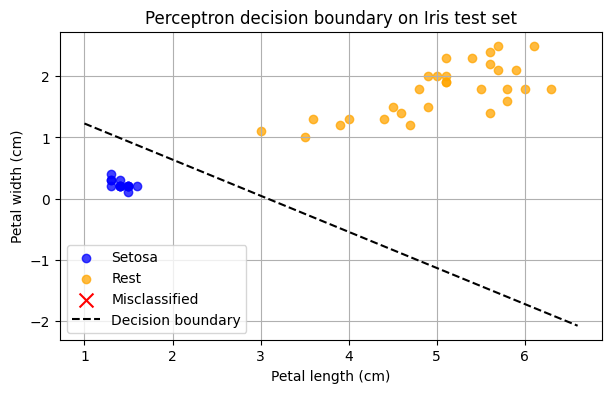

Misclassified test points: 0 out of 45


In [11]:
fig, ax = plt.subplots()
for cls, color, label in [(1, "blue", "Setosa"), (0, "orange", "Rest")]:
    mask = y_test == cls
    ax.scatter(X_test[mask,0], X_test[mask,1], c=color, label=label, alpha=0.75)
wrong = y_pred != y_test
ax.scatter(X_test[wrong,0], X_test[wrong,1], c="red", marker="x", s=100, label="Misclassified")
plot_boundary(ax, iris_perc.coef_[0], iris_perc.intercept_[0],
              x_min=X_test[:,0].min()-0.3, x_max=X_test[:,0].max()+0.3)
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.set_title("Perceptron decision boundary on Iris test set")
ax.legend()
plt.show()
print("Misclassified test points:", int(wrong.sum()), "out of", len(y_test))

**Interpretation:** The decision boundary is straight because a single perceptron uses a linear equation, `w·x + b = 0`. The number of misclassified points is printed above; Setosa is generally well separated from the other Iris classes using petal measurements.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
rate_results = []
rate_predictions = {}
for rate in [0.001, 0.1, 10.0]:
    model = Perceptron(eta0=rate, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rate_predictions[rate] = pred
    rate_results.append({
        "eta0": rate,
        "accuracy": accuracy_score(y_test, pred),
        "n_iter_": model.n_iter_,
        "coef_": model.coef_[0].round(4).tolist()
    })
rate_df = pd.DataFrame(rate_results)
display(rate_df)
print("Predictions identical to eta0=0.001:")
for rate in [0.1, 10.0]:
    print(rate, np.array_equal(rate_predictions[0.001], rate_predictions[rate]))

,eta0,accuracy,n_iter_,coef_
0,0.001,1.0,6,"[-0.0013, -0.0022]"
1,0.100,1.0,7,"[-0.13, -0.22]"
2,10.000,1.0,7,"[-13.0, -22.0]"


Predictions identical to eta0=0.001:
0.1 True
10.0 True


**Interpretation:** The learning rate controls the size of each weight and bias update after a mistake. Because training starts from zero, changing the learning rate can change the scale of the learned coefficients and may also change predictions or the number of epochs.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
X_multi = iris.data
y_multi = iris.target
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.30, random_state=42, stratify=y_multi
)
multi_perc = Perceptron(random_state=42, max_iter=1000)
multi_perc.fit(X_train_multi, y_train_multi)
multi_pred = multi_perc.predict(X_test_multi)
print("Classification report:\n", classification_report(y_test_multi, multi_pred, target_names=iris.target_names, zero_division=0))
cm_multi = confusion_matrix(y_test_multi, multi_pred)
print("Confusion matrix:\n", cm_multi)
print("coef_.shape:", multi_perc.coef_.shape)
print("Rows of coef_ correspond to the class-specific one-vs-rest weight vectors.")

Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)
Rows of coef_ correspond to the class-specific one-vs-rest weight vectors.


**Interpretation:** Each row of `coef_` represents the learned weights for one class in the one-vs-rest setup. The class with the lowest recall in the printed report is the hardest to classify; use the confusion matrix to see which class is most often confused with another.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
log_model = LogisticRegression(random_state=42, max_iter=200)
log_model.fit(X_train_multi, y_train_multi)
log_pred = log_model.predict(X_test_multi)

comparison = pd.DataFrame([
    {"Model": "Perceptron", "Accuracy": accuracy_score(y_test_multi, multi_pred),
     "Macro-F1": f1_score(y_test_multi, multi_pred, average="macro")},
    {"Model": "Logistic Regression", "Accuracy": accuracy_score(y_test_multi, log_pred),
     "Macro-F1": f1_score(y_test_multi, log_pred, average="macro")}
])
display(comparison)

,Model,Accuracy,Macro-F1
0,Perceptron,0.666667,0.549853
1,Logistic Regression,0.933333,0.933259


**Interpretation:** Logistic Regression can perform better because it uses a smooth sigmoid-based objective and gradient information during training. The perceptron uses a hard step decision and updates only when a sample is misclassified, providing less informative feedback during learning.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Answer Q1:**  
\(z = w\cdot x + b = (0.5)(1) + (-0.3)(2) + 0.2 = 0.1\).  
Since \(z \geq 0\), \(\hat y = 1\). Therefore \(e = y-\hat y = 0-1=-1\).  
Update: \(w_1=0.5+0.1(-1)(1)=0.4\), \(w_2=-0.3+0.1(-1)(2)=-0.5\), and \(b=0.2+0.1(-1)=0.1\).

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Answer Q2:**  
The boundary is \(0.3x_1+0.2x_2-0.4=0\), or \(x_2=2-1.5x_1\).  
At \((1,1)\), \(z=0.3+0.2-0.4=0.1\geq0\), so the point is on the class-1 side and \(\hat y=1\).

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**Answer Q3:**  
(a) The constraints require \(b<0\), \(w_2+b\geq0\), \(w_1+b\geq0\), and \(w_1+w_2+b<0\). Adding the middle two inequalities gives \(w_1+w_2+2b\geq0\). Since \(b<0\), this alone is not the contradiction; instead, from \(w_1\geq-b\) and \(w_2\geq-b\), we get \(w_1+w_2+b\geq-b>0\), contradicting the required \(w_1+w_2+b<0\).  
(b) The plot below shows class 1 at opposite corners and class 0 at the other two corners, so a single straight line cannot separate them.  
(c) Use a multilayer perceptron with at least one hidden layer and a nonlinear activation function.

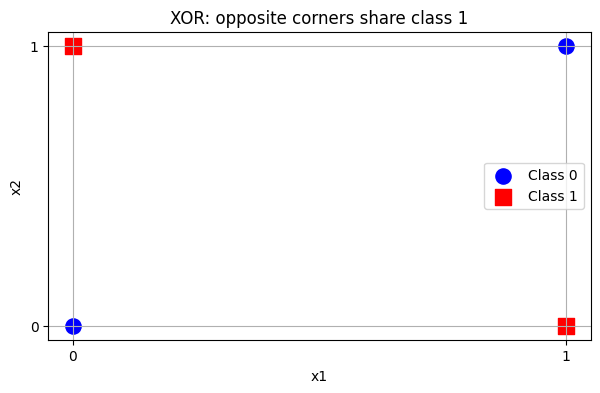

In [15]:
# XOR layout for graded question Q3
fig, ax = plt.subplots()
for cls, color, marker, label in [(0, "blue", "o", "Class 0"), (1, "red", "s", "Class 1")]:
    ax.scatter(X_xor[y_xor==cls,0], X_xor[y_xor==cls,1], c=color, marker=marker, s=120, label=label)
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("XOR: opposite corners share class 1")
ax.legend(); plt.show()

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
X_iris_3 = iris.data[:, (0, 2, 3)]
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X_iris_3, y_setosa, test_size=0.30, random_state=42, stratify=y_setosa
)
iris_perc_3 = Perceptron(random_state=42)
iris_perc_3.fit(X_train_3, y_train_3)
pred_3 = iris_perc_3.predict(X_test_3)
acc_3 = accuracy_score(y_test_3, pred_3)
f1_3 = f1_score(y_test_3, pred_3, average="macro")
acc_2 = accuracy_score(y_test, y_pred)
f1_2 = f1_score(y_test, y_pred, average="macro")
print(f"Original features (2,3): accuracy={acc_2:.4f}, macro-F1={f1_2:.4f}")
print(f"Extended features (0,2,3): accuracy={acc_3:.4f}, macro-F1={f1_3:.4f}")

Original features (2,3): accuracy=1.0000, macro-F1=1.0000
Extended features (0,2,3): accuracy=1.0000, macro-F1=1.0000


**Analysis:** Compare the two printed accuracy and macro-F1 values. The extra sepal-length feature helps only if the extended model's metric values are higher; otherwise, it does not improve this split.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Hand-built perceptron accuracy: 0.8666666666666667
Hand-built epochs: 1000 | final w: [ 0.28706471 -0.04596483] | final b: 0.10000000000000003
sklearn perceptron accuracy: 0.7666666666666667
sklearn n_iter_: 14 | coef_: [ 0.11605057 -0.0199037 ] | intercept_: 0.10000000000000003


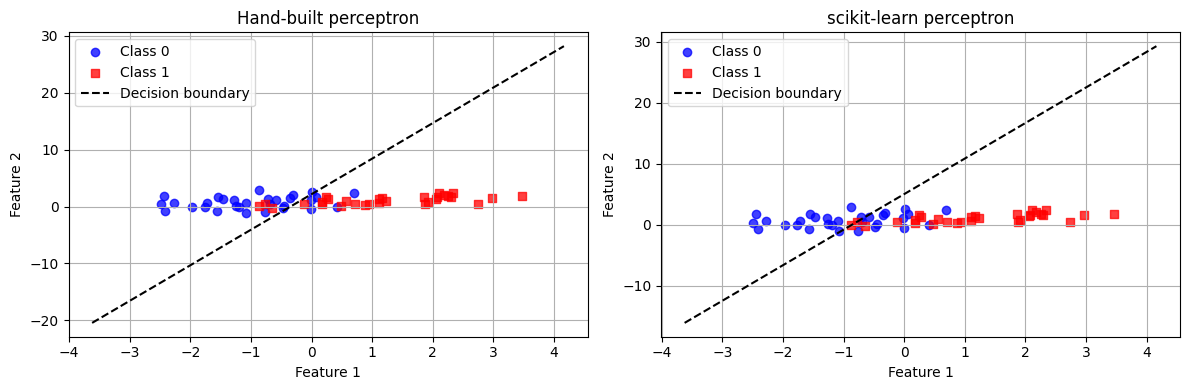

In [17]:
X_syn, y_syn = make_classification(
    n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1,
    random_state=42
)
X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(
    X_syn, y_syn, test_size=0.30, random_state=42, stratify=y_syn
)

w_hand, b_hand, hist_hand = train_perceptron(X_syn_train, y_syn_train, eta=0.1, max_epochs=1000)
hand_pred = np.array([predict(w_hand, x, b_hand) for x in X_syn_test])
sk_syn = Perceptron(random_state=42, max_iter=1000, eta0=0.1)
sk_syn.fit(X_syn_train, y_syn_train)
sk_pred = sk_syn.predict(X_syn_test)

print("Hand-built perceptron accuracy:", accuracy_score(y_syn_test, hand_pred))
print("Hand-built epochs:", len(hist_hand), "| final w:", w_hand, "| final b:", b_hand)
print("sklearn perceptron accuracy:", accuracy_score(y_syn_test, sk_pred))
print("sklearn n_iter_:", sk_syn.n_iter_, "| coef_:", sk_syn.coef_[0], "| intercept_:", sk_syn.intercept_[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, w_plot, b_plot, title in [
    (axes[0], w_hand, b_hand, "Hand-built perceptron"),
    (axes[1], sk_syn.coef_[0], sk_syn.intercept_[0], "scikit-learn perceptron")
]:
    for cls, color, marker, label in [(0, "blue", "o", "Class 0"), (1, "red", "s", "Class 1")]:
        ax.scatter(X_syn_test[y_syn_test==cls,0], X_syn_test[y_syn_test==cls,1],
                   c=color, marker=marker, label=label, alpha=0.75)
    plot_boundary(ax, w_plot, b_plot,
                  x_min=X_syn[:,0].min()-0.5, x_max=X_syn[:,0].max()+0.5)
    ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

**Analysis:** Compare test accuracy, epoch count, and learned parameters printed above. The two implementations follow the same perceptron update idea, but their exact coefficients and stopping behavior can differ because of implementation details and training order.